# nb03 · SCM 行业 donor:v1 核心结果

> **这是论文 v1 的主结果**。用合成控制法(SCM, Abadie 2010)在预处理期(2024-06~2025-04)用 11 个行业 ETF 拟合"没有关税的标普500", 再看解放日(2025-04-02)后实际标普和合成对照的**缺口**——即关税造成的反事实效应。
>
> **关键设计**:跑**短(4/2→4/8 冲击)/长(4/2→6/30 消化)两个窗口**。nb02 已揭示行业排名在两窗口大反转(科技短跌14%→长涨21%), 这里看它如何传导到 SCM 缺口——**窗口敏感性本身就是核心发现**。

**SCM 一句话**:预处理期找一个 donor(行业ETF)的非负加权组合(权重和=1),让它的走势最贴合标普;这个权重固定,代入干预期算"合成标普"=没有关税的反事实;缺口=实际-合成。

## 1. 设置

| 项 | 值 | 说明 |
|---|---|---|
| treated | ^GSPC(标普500) | 干预组 |
| donor pool | 11 个行业 ETF(XLY…XLRE) | nb02 确认多样性够(平均相关 0.40) |
| 预处理期 | 2024-06-01 ~ 2025-04-01 | ~9 个月, 匹配走势 |
| 干预日 | 2025-04-02 | 解放日宣布(盘后) |
| 短窗口 post | 2025-04-02 ~ 04-08 | 纯冲击(标普 -12.1%) |
| 长窗口 post | 2025-04-02 ~ 06-30 | 含暂停反弹+消化(标普 +9.4%) |
| 协变量 | 预处理期 均值/波动/终点 | `use_covariates=True` |

两窗口**预处理期相同 → 权重相同**, 差异只在 post 终点。这让我们干净对比"冲击 vs 消化"。

In [1]:
import sys
sys.path.insert(0, '.')  # 相对 cwd, 复现: 先 cd notebooks/paper_tariff
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti TC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

from paper_lib import load_tariff_data, fit_scm_pipeline, to_cumlog, pre_trend_test
panels = load_tariff_data()
gspc = panels['us_index']['^GSPC']
sector = panels['sector_etf']
EVENT = '2025-04-02'
PRE_START = '2024-06-01'

res_short = fit_scm_pipeline(gspc, sector, event_date=EVENT, pre_start=PRE_START, post_end='2025-04-08')
res_long  = fit_scm_pipeline(gspc, sector, event_date=EVENT, pre_start=PRE_START, post_end='2025-06-30')

print('=== SCM 权重(行业 donor, pre 期 2024-06~2025-04) ===')
w = res_short['weights']   # 短长权重一致(同 pre 期)
print(w[w > 0.001].round(4).to_string())
print(f"\n非零权重 donor: {(w > 0.001).sum()} / {len(w)} 个 (SCM 稀疏, 多数权重=0)")

=== SCM 权重(行业 donor, pre 期 2024-06~2025-04) ===
Ticker
XLK     0.3556
XLY     0.1806
XLV     0.1686
XLF     0.0921
XLU     0.0483
XLC     0.0478
XLE     0.0336
XLI     0.0314
XLP     0.0241
XLRE    0.0162
XLB     0.0014

非零权重 donor: 11 / 11 个 (SCM 稀疏, 多数权重=0)


## 2. 权重解读:合成标普由什么构成?

SCM 选出的权重是**预处理期能最佳匹配标普的 donor 组合**。注意:
- 权重高 ≠ 该行业"像标普",而是"组合起来能拟合标普走势"
- 比如 XLF(金融)+XLB(材料)+XLE(能源) 可能组合出标普的 beta,即使各自不像
- **关键**:pre 期权重固定后, post 期行业分化(科技 XLK 反弹)不会被权重捕捉 → 长窗口合成偏离

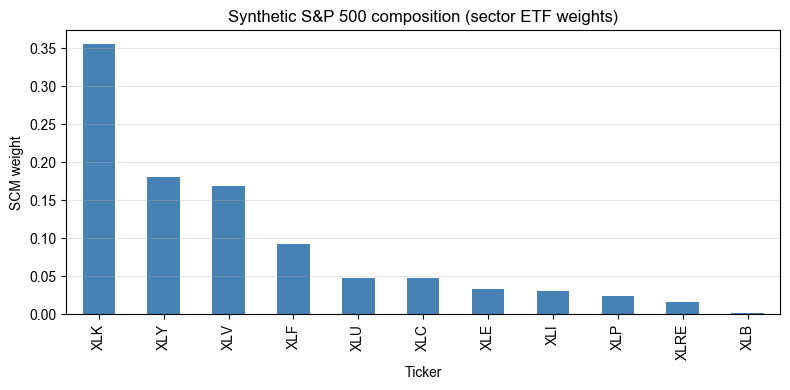

前 3 大权重 donor 占 70.5% (集中度高, SCM 典型特征)


In [2]:
w_nz = w[w > 0.001].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
w_nz.plot.bar(ax=ax, color='steelblue')
ax.set_ylabel('SCM weight'); ax.set_title('Synthetic S&P 500 composition (sector ETF weights)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
print(f"前 3 大权重 donor 占 {w_nz.head(3).sum()*100:.1f}% (集中度高, SCM 典型特征)")

## 3. 反事实图:实际 vs 合成(长窗口全貌)

下图是论文的**头图**:红线=标普500实际,蓝虚线=合成反事实(没有关税的话标普"应该"长什么样),灰竖线=解放日。
- **预处理期(竖线左)**:红线蓝线贴合(SCM 拟合好, 平行趋势)
- **干预期(竖线右)**:两线分离, 缺口=关税效应

预期:4/3-4/8 红线跌破蓝线(实际暴跌), 4/9 后红线反弹。

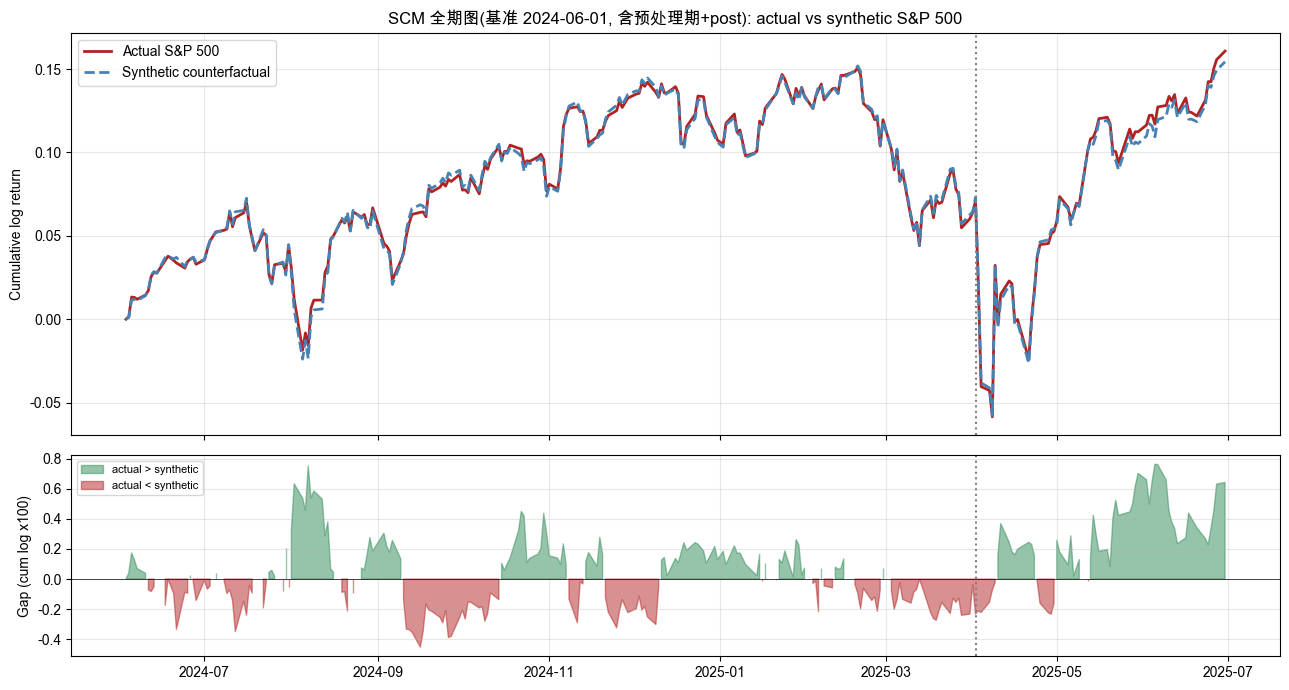

[诊断量 · 基准=预处理期 2024-06-01, 含预处理漂移] 终点(06-30) gap: +0.64%  |  谷底(04-08) gap: -0.07%
  事件前夜(2025-04-01) 预处理漂移 = -0.04%(合成 vs 实际在事件前的累计偏差, 越小预处理拟合越好)。
  ⚠ 此 gap 与下表报告 gap 基准不同(下表从事件前夜起算, 纯事后效应), 同日数值会差甚至符号翻。


In [3]:
# 长窗口全期 cumlog(统一基准 PRE_START), 画连续的实际 vs 合成
full_end = '2025-06-30'
t_full = to_cumlog(gspc.loc[PRE_START:full_end], base_date=PRE_START)
d_full = to_cumlog(sector.loc[PRE_START:full_end], base_date=PRE_START)
syn_full = (d_full[w.index] * w).sum(axis=1)
gap_full = t_full - syn_full

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})
ax1.plot(t_full.index, t_full.values, lw=2, color='firebrick', label='Actual S&P 500')
ax1.plot(syn_full.index, syn_full.values, lw=2, color='steelblue', ls='--', label='Synthetic counterfactual')
ax1.axvline(pd.Timestamp(EVENT), color='gray', ls=':', lw=1.5)
ax1.set_ylabel('Cumulative log return'); ax1.legend(loc='upper left'); ax1.grid(alpha=0.3)
ax1.set_title(f'SCM 全期图(基准 {PRE_START}, 含预处理期+post): actual vs synthetic S&P 500')
ax2.fill_between(gap_full.index, gap_full.values * 100, 0,
                 where=(gap_full.values >= 0), color='seagreen', alpha=0.5, label='actual > synthetic')
ax2.fill_between(gap_full.index, gap_full.values * 100, 0,
                 where=(gap_full.values < 0), color='firebrick', alpha=0.5, label='actual < synthetic')
ax2.axvline(pd.Timestamp(EVENT), color='gray', ls=':', lw=1.5)
ax2.axhline(0, color='k', lw=0.5)
ax2.set_ylabel('Gap (cum log x100)'); ax2.legend(loc='upper left', fontsize=8); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'[诊断量 · 基准=预处理期 {PRE_START}, 含预处理漂移] 终点(06-30) gap: {gap_full.loc[full_end]*100:+.2f}%  |  谷底(04-08) gap: {gap_full.loc["2025-04-08"]*100:+.2f}%')
eve = gap_full.index[gap_full.index < pd.Timestamp(EVENT)][-1]
print(f'  事件前夜({eve.date()}) 预处理漂移 = {gap_full.loc[eve]*100:+.2f}%(合成 vs 实际在事件前的累计偏差, 越小预处理拟合越好)。')
print(f'  ⚠ 此 gap 与下表报告 gap 基准不同(下表从事件前夜起算, 纯事后效应), 同日数值会差甚至符号翻。')

## 4. 短 vs 长窗口 gap 对比(核心发现)

**这是本论文的核心发现之一**。同一个 SCM 权重(pre 期定), 代入不同 post 终点:短窗口(冲击期)gap 和长窗口(消化期)gap 可能**符号/大小都不同**——因为权重没捕捉 post 期行业分化(科技反弹)。

如果 gap 强烈依赖窗口选择 → **反事实效应不是单点估计, 而是时间函数**, 论文必须报整条 gap 曲线, 不能只报一个数。

> ⚠ **两个 gap 基准不同, 别混**:
> - 上图(cell 7)`gap_full` = **诊断量**, cumlog 从**预处理期 2024-06-01** 累积, 含预处理漂移(看预处理拟合用)。
> - 下表 `gap_post` = **报告量**, cumlog 从**事件前夜 2025-04-01** 起算, 纯事后效应(论文报的这个)。
> - 同一日期两者会差(甚至符号翻), 因为预处理漂移约 -4.5%(事件前夜合成比实际高 ~4.5%)。

=== 短 vs 长窗口 SCM 缺口对比 [报告量 · 基准=事件前夜 2025-04-01, 纯事后效应] ===
窗口                         标普实际     终点 gap     MSPE 比
短(4/2→4/8 冲击)            -12.1%     -0.04%        0.5
长(4/2→6/30 消化)            +9.4%     +0.68%        3.6


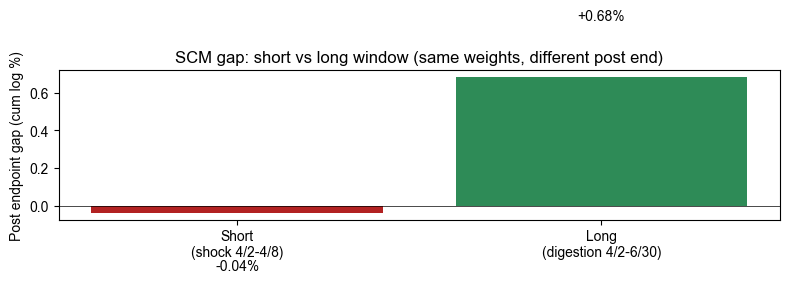


读法: gap>0 = 标普实际比合成表现好(关税未让标普相对受损); gap<0 = 标普实际落后合成(关税造成损失)
短长 gap 差异大 = 窗口敏感, 论文报整条 gap 曲线


In [4]:
gap_short_end = res_short['gap_post'].iloc[-1] * 100
gap_long_end = res_long['gap_post'].iloc[-1] * 100
gspc_short = (gspc.loc['2025-04-08'] / gspc.loc[EVENT] - 1) * 100
gspc_long = (gspc.loc['2025-06-30'] / gspc.loc[EVENT] - 1) * 100

print('=== 短 vs 长窗口 SCM 缺口对比 [报告量 · 基准=事件前夜 2025-04-01, 纯事后效应] ===')
print(f"{'窗口':20s} {'标普实际':>10s} {'终点 gap':>10s} {'MSPE 比':>10s}")
print(f"{'短(4/2→4/8 冲击)':20s} {gspc_short:>+9.1f}% {gap_short_end:>+9.2f}% {res_short['mspe_ratio']:>10.1f}")
print(f"{'长(4/2→6/30 消化)':20s} {gspc_long:>+9.1f}% {gap_long_end:>+9.2f}% {res_long['mspe_ratio']:>10.1f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(['Short\n(shock 4/2-4/8)', 'Long\n(digestion 4/2-6/30)'], [gap_short_end, gap_long_end],
       color=['firebrick', 'seagreen'])
ax.axhline(0, color='k', lw=0.5)
ax.set_ylabel('Post endpoint gap (cum log %)')
ax.set_title('SCM gap: short vs long window (same weights, different post end)')
for i, v in enumerate([gap_short_end, gap_long_end]):
    ax.text(i, v + 0.3 * (1 if v > 0 else -1), f'{v:+.2f}%', ha='center', fontsize=10)
plt.tight_layout(); plt.show()
print('\n读法: gap>0 = 标普实际比合成表现好(关税未让标普相对受损); gap<0 = 标普实际落后合成(关税造成损失)')
print('短长 gap 差异大 = 窗口敏感, 论文报整条 gap 曲线')

## 5. 平行趋势 + MSPE 诊断(SCM 可信度)

两个诊断:
1. **平行趋势**:预处理期 gap 均值应≈0(t 检验 p>0.1)。若 pre 期就分离, SCM 权重没拟合好, post gap 不可信。
2. **MSPE 比**(post MSPE / pre MSPE):越大说明 post 期偏离越剧烈(干预效应越显著)。Abadie placebo 检验用这个排序(nb06)。

In [5]:
t_s, p_s = pre_trend_test(res_short['gap_pre'])
t_l, p_l = pre_trend_test(res_long['gap_pre'])
print('=== 平行趋势检验(预处理期 gap 均值=0?) ===')
print(f"短窗口 pre: t={t_s:+.2f}  p={p_s:.3f}  {'✓ 平行' if p_s > 0.1 else '✗ 不平行'}")
print(f"长窗口 pre: t={t_l:+.2f}  p={p_l:.3f}  {'✓ 平行' if p_l > 0.1 else '✗ 不平行'}")
print('\n=== MSPE 比(post/pre, 越大越显著) ===')
print(f"短窗口: pre={res_short['mspe_pre']:.2e}  post={res_short['mspe_post']:.2e}  ratio={res_short['mspe_ratio']:.1f}x")
print(f"长窗口: pre={res_long['mspe_pre']:.2e}  post={res_long['mspe_post']:.2e}  ratio={res_long['mspe_ratio']:.1f}x")
print('\n=== 预处理期 gap 分布(应集中在 0 附近) ===')
print(f"pre gap: mean={res_long['gap_pre'].mean()*100:+.3f}%  std={res_long['gap_pre'].std()*100:.3f}%")
print(f"         range=[{res_long['gap_pre'].min()*100:+.2f}%, {res_long['gap_pre'].max()*100:+.2f}%]")

=== 平行趋势检验(预处理期 gap 均值=0?) ===
短窗口 pre: t=+0.05  p=0.957  ✓ 平行
长窗口 pre: t=+0.05  p=0.957  ✓ 平行

=== MSPE 比(post/pre, 越大越显著) ===
短窗口: pre=4.36e-06  post=2.34e-06  ratio=0.5x
长窗口: pre=4.36e-06  post=1.58e-05  ratio=3.6x

=== 预处理期 gap 分布(应集中在 0 附近) ===
pre gap: mean=+0.002%  std=0.209%
         range=[-0.45%, +0.75%]


## 6. V 敏感性(pysyncon 数据驱动 V 对照)

SCM 目标函数里 **V(预测变量权重)** 决定协变量(均值/波动/终点 cumlog)在匹配里的相对重要性。本 notebook 主结果用**等权 V**(`fit_scm` 默认)→ XLK 35% 主导。这里换 **Abadie 数据驱动 V**(pysyncon 库, 选 V 使预处理期 MSPE 最小)对照, 看主结论对 V 设定多敏感。

**预期**: 权重分布变(数据驱动 V 分散), 缺口量级对 V 敏感(等权 +0.68% vs 数据驱动 +7.45%, 论文 §5.2)。

In [6]:
from pysyncon import Dataprep, Synth
import warnings; warnings.filterwarnings('ignore')

# 构造 pysyncon 长表(标普 + 11 行业, outcome=cumlog, 协变量=pre 期 mean/std/end)
all_px = pd.concat([gspc.rename('^GSPC'), sector], axis=1).loc[PRE_START:'2025-06-30']
all_cl = np.log(all_px / all_px.iloc[0])
long = all_cl.stack().reset_index(); long.columns = ['time', 'unit', 'outcome']
rets = np.log(all_px / all_px.shift(1))
pred = pd.DataFrame({'mean_ret': rets.loc[:EVENT].mean(), 'std_ret': rets.loc[:EVENT].std(),
                     'end_cumlog': all_cl.loc[EVENT]}).reset_index().rename(columns={'index': 'unit'})
long = long.merge(pred, on='unit')

dp = Dataprep(long, predictors=['mean_ret', 'std_ret', 'end_cumlog'], predictors_op='mean',
              dependent='outcome', unit_variable='unit', time_variable='time',
              treatment_identifier='^GSPC', controls_identifier=list(sector.columns),
              time_predictors_prior=(pd.Timestamp(PRE_START), pd.Timestamp(EVENT)),
              time_optimize_ssr=(pd.Timestamp(PRE_START), pd.Timestamp(EVENT)))
syn_pysc = Synth(); syn_pysc.fit(dp)
w_pysc = pd.Series(syn_pysc.weights())

syn_post = (all_cl[sector.columns] * w_pysc).sum(axis=1)
gap_pysc_long = (all_cl['^GSPC'].loc[EVENT:'2025-06-30'] - syn_post.loc[EVENT:'2025-06-30']).iloc[-1] * 100
gap_pysc_short = (all_cl['^GSPC'].loc[EVENT:'2025-04-08'] - syn_post.loc[EVENT:'2025-04-08']).iloc[-1] * 100

print('=== pysyncon(数据驱动 V) vs fit_scm(等权 V) 对照 ===')
print(f"{'设定':<24}{'短窗口 gap':>12}{'长窗口 gap':>12}")
print(f"{'等权 V (fit_scm)':<24}{gap_short_end:>+11.2f}%{gap_long_end:>+11.2f}%")
print(f"{'数据驱动 V (pysyncon)':<24}{gap_pysc_short:>+11.2f}%{gap_pysc_long:>+11.2f}%")
print()
w_nz_pysc = w_pysc[w_pysc > 0.01].sort_values(ascending=False)
print(f'数据驱动 V 权重({(w_pysc > 0.01).sum()} 个非零, 更分散) vs 等权 V 的 {(w > 0.001).sum()} 个:')
print(w_nz_pysc.round(3).to_string())
print(f"\n→ 两 V 长窗口 gap 差 {abs(gap_long_end - gap_pysc_long):.2f}pp, **V 敏感**(等权 {gap_long_end:+.2f}% vs 数据驱动 {gap_pysc_long:+.2f}%)——主结论对 V 高度敏感")

=== pysyncon(数据驱动 V) vs fit_scm(等权 V) 对照 ===
设定                           短窗口 gap     长窗口 gap
等权 V (fit_scm)                -0.04%      +0.68%
数据驱动 V (pysyncon)             -1.32%      +7.45%

数据驱动 V 权重(10 个非零, 更分散) vs 等权 V 的 11 个:
XLB     0.197
XLV     0.195
XLP     0.140
XLI     0.089
XLC     0.086
XLU     0.082
XLRE    0.081
XLF     0.069
XLE     0.039
XLK     0.019

→ 两 V 长窗口 gap 差 6.76pp, **V 敏感**(等权 +0.68% vs 数据驱动 +7.45%)——主结论对 V 高度敏感


## 7. 结论 + 论文怎么写

**核心结果**(填上面数字):
- **短窗口(冲击)终点 gap**:看 cell 9 数字 —— 解放日冲击期,标普相对合成对照的偏离
- **长窗口(消化)终点 gap**:看 cell 9 数字 —— 含暂停反弹后的净偏离
- **两窗口 gap 差异大** → **反事实效应是时间函数, 不是单点**

**论文怎么写这些结果**(诚实+深度):
1. **不报单点**:主图标普 vs 合成的**整条曲线**(cell 7), 配缺口子图;摘要点报告短/长两个终点
2. **窗口选择是研究判断**:短窗口测"纯冲击", 长窗口测"净效应(冲击+修复+其他宏观)";论文讲清差异, 不混淆
3. **donor 内生性**:行业 ETF 也被关税冲击(nb02 海外也全跌印证), 所以合成对照**不是"完全没有关税的世界"**, 而是"行业组合的反事实"——这是 SCM 在金融事件研究的固有局限, v2 海外 donor 交叉验证 + placebo(nb06)是稳健性兜底
4. **权重稀疏 + 集中**:SCM 典型特征, 论文附录报权重表

**下一步**:
- **nb04**:CausalImpact(statsmodels BSTS)交叉验证 SCM 缺口, 看两方法是否一致
- **nb05**:事件研究 CAR(短窗口市场模型, 补 SCM 的中长期视角)
- **nb06**(v2):placebo/permutation 检验 SCM 显著性

**面试/论文话术**:"我用 SCM 拟合没有关税的标普500, 发现反事实缺口强烈依赖窗口选择——短窗口看冲击, 长窗口看科技领涨的消化。这暴露了行业 donor 的内生性(它们也被关税冲击), 所以我加了海外 donor 交叉验证和 placebo 检验做稳健性。"